# 02 · Candidates, list ranks and seats — does attention win seats, or do seats win attention?

Turkey elects MPs by **closed-list proportional representation**: a candidate wins iff their **rank on the party list ≤ the
number of seats that list wins in the district**. So *within* a list, Twitter cannot decide who gets elected — the party
does, when it sets the ranks. That gives three sharper questions than "did elected politicians have more followers?":

1. **Selection** — do parties give electable ranks to politicians who are big / growing on Twitter?
2. **Anticipation** — after the lists are published (9–19 April 2023), do candidates in electable slots gain followers faster?
3. **Seat effect** — comparing candidates *just inside* vs *just outside* the seat cutoff, does winning a seat itself bring followers?

**New data:** official final candidate lists (Resmî Gazete, 19 Apr 2023, No. 32168 Mükerrer), OCR'd from the scanned PDF
→ 12,992 candidates in 87 districts (see `src/ocr/`). Linked to 574/600 elected MPs and to 655 #Secim2023 Twitter accounts.

`margin = rank − seats won by the list` → **margin ≤ 0: elected · margin ≥ 1: not elected**.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.dates as mdates
from scipy import stats
from pathlib import Path
ROOT = Path('..'); FIG = ROOT / 'figures'
INK, MUTED, GRID = '#1f2328', '#6e7781', '#e6e8eb'
WIN, LOSE = '#0077B6', '#F28C00'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
                     'font.size': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'text.color': INK, 'axes.labelcolor': INK, 'figure.dpi': 110})

cand  = pd.read_csv(ROOT / 'data/processed/candidates_linked.csv', dtype={'twitter_id': str})
daily = pd.concat([pd.read_csv(f, parse_dates=['date'], dtype={'id': str}) for f in sorted((ROOT / 'data/processed').glob('daily_panel_*.csv.gz'))], ignore_index=True)
print(f"{len(cand):,} candidates · {cand.district.nunique()} districts · {cand.party.nunique()} lists · "
      f"{cand.elected.sum()} elected found · {cand.twitter_id.notna().sum()} with a Twitter account in #Secim2023")

12,992 candidates · 87 districts · 25 lists · 573 elected found · 638 with a Twitter account in #Secim2023


## 1 · Data checks

In [2]:
seats = cand.groupby('district').elected.sum()
print('Rank-cutoff rule reproduces elected flag:', f"{((cand.margin <= 0) == cand.elected).mean():.1%}")
display(cand.groupby('list').agg(candidates=('rank', 'size'), elected=('elected', 'sum'),
                                 with_twitter=('twitter_id', lambda s: s.notna().sum())).sort_values('elected', ascending=False))
display(cand.education.value_counts(normalize=True).round(3).to_frame('share of all candidates'))

Rank-cutoff rule reproduces elected flag: 99.8%


,candidates,elected,with_twitter
list,,,
AKP,598,255,226
CHP,581,166,155
YSGP,600,56,65
MHP,600,48,64
IYI,565,39,45
YRP,600,5,6
TİP,398,4,4
other,9050,0,73


,share of all candidates
education,
YÜKSEK,0.501
ORTA,0.398
İLK,0.101


In [3]:
# Analysis sample: candidates on seat-winning lists who have a Twitter account in the panel
t = cand[cand.twitter_id.notna() & (cand.list != 'other')].set_index('twitter_id').copy()
d = daily[daily.id.isin(t.index)]

def followers_at(day, window=5):
    day = pd.Timestamp(day)
    return d[d.date.between(day - pd.Timedelta(days=window), day)].sort_values('date').groupby('id').followers.last()

snap = {k: followers_at(v) for k, v in {'dec01': '2022-12-01', 'feb05': '2023-02-05', 'mar25': '2023-03-25',
                                        'apr08': '2023-04-08', 'may13': '2023-05-13', 'jun30': '2023-06-30'}.items()}
for k, v in snap.items():
    t[k] = v
g = lambda a, b: 100 * (t[b] - t[a]) / t[a]
t['growth_pre']        = g('dec01', 'feb05')   # long before lists
t['growth_prelist']    = g('mar25', 'apr08')   # two weeks before lists were submitted
t['growth_campaign']   = g('apr08', 'may13')   # lists known -> election day
t['growth_postelect']  = g('may13', 'jun30')   # after the result
t['elected_'] = np.where(t.margin <= 0, 'Elected', 'Not elected')
t['mbin'] = t.margin.clip(-4, 4)
print(len(t), 'candidates in the analysis sample'); display(t.elected_.value_counts())

565 candidates in the analysis sample


elected_
Elected        477
Not elected     88
Name: count, dtype: int64

## 2 · The picture in one figure: placement, momentum and the seat cutoff

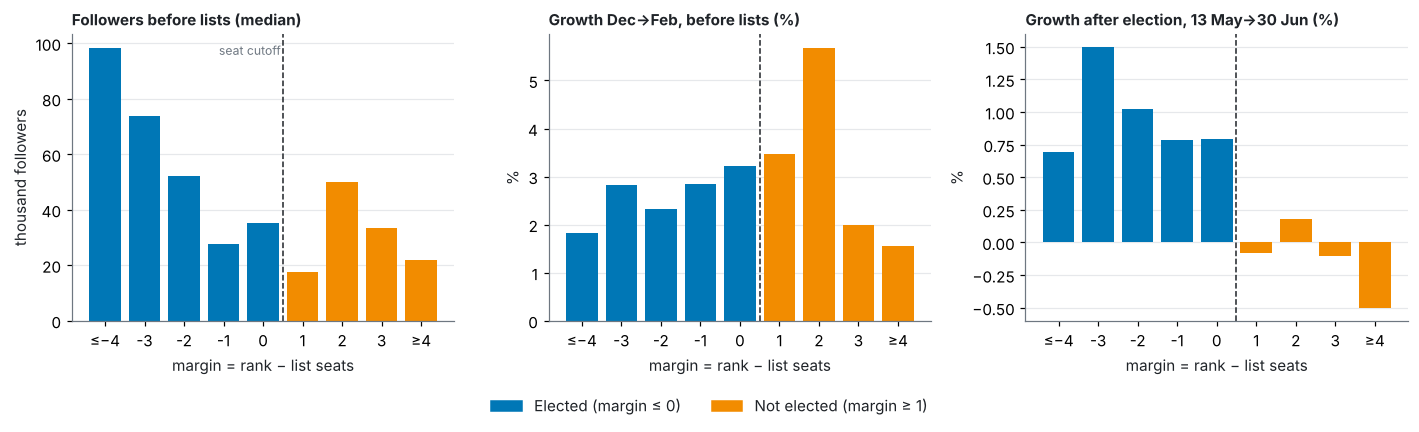

,n,followers,growth_pre,growth_post
mbin,,,,
-4.0,73,98304.0,1.83,0.69
-3.0,38,73943.0,2.82,1.49
-2.0,59,52250.0,2.33,1.02
-1.0,94,27583.5,2.85,0.79
0.0,213,35163.0,3.21,0.79
1.0,55,17592.0,3.47,-0.08
2.0,9,49846.5,5.68,0.18
3.0,10,33560.5,1.99,-0.10
4.0,14,22053.5,1.56,-0.50


In [4]:
prof = t.groupby('mbin').agg(n=('rank', 'size'),
                             followers=('dec01', 'median'),
                             growth_pre=('growth_pre', 'median'),
                             growth_post=('growth_postelect', 'median'))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
specs = [('followers', 'Followers before lists (median)', lambda v: v / 1e3, 'thousand followers'),
         ('growth_pre', 'Growth Dec→Feb, before lists (%)', lambda v: v, '%'),
         ('growth_post', 'Growth after election, 13 May→30 Jun (%)', lambda v: v, '%')]
for ax, (col, title, f, ylab) in zip(axes, specs):
    x = prof.index.values; y = f(prof[col].values)
    ax.bar(x, y, width=0.8, color=[WIN if xi <= 0 else LOSE for xi in x])
    ax.axvline(0.5, color=INK, lw=1, ls='--')
    ax.set_title(title, fontsize=10); ax.set_ylabel(ylab); ax.grid(axis='x', visible=False)
    ax.set_xticks(x); ax.set_xticklabels(['≤−4' if v == -4 else ('≥4' if v == 4 else f'{int(v)}') for v in x])
    ax.set_xlabel('margin = rank − list seats')
axes[0].text(0.45, 0.97, 'seat cutoff', transform=axes[0].get_xaxis_transform(), ha='right', va='top', fontsize=8, color=MUTED)
handles = [plt.Rectangle((0, 0), 1, 1, color=WIN), plt.Rectangle((0, 0), 1, 1, color=LOSE)]
fig.legend(handles, ['Elected (margin ≤ 0)', 'Not elected (margin ≥ 1)'], loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.savefig(FIG / '07_margin_profiles.png', dpi=200, bbox_inches='tight'); plt.show()
display(prof.round(2))

Reading left → right: candidates placed **higher on the list have bigger accounts**, but they were **not growing faster**
before the lists, and **only those who end up inside the cutoff gain followers after the election**.

## 3 · H2a — Selection: does Twitter predict an electable rank?

In [5]:
rows = []
for lst, grp in t.groupby('list'):
    if len(grp) < 30: continue
    r1 = stats.spearmanr(grp['rank'], np.log10(grp.dec01), nan_policy='omit')
    r2 = stats.spearmanr(grp['rank'], grp.growth_pre, nan_policy='omit')
    rows.append({'list': lst, 'n': len(grp), 'ρ(rank, log followers)': r1.statistic, 'p (size)': r1.pvalue,
                 'ρ(rank, pre-growth)': r2.statistic, 'p (growth)': r2.pvalue})
display(pd.DataFrame(rows).set_index('list').round(3))

a, b = t.loc[t.margin <= 0, 'growth_pre'].dropna(), t.loc[t.margin >= 1, 'growth_pre'].dropna()
print(f"Pre-list growth, electable vs not: medians {a.median():.2f}% vs {b.median():.2f}%  (Mann–Whitney p = {stats.mannwhitneyu(a, b).pvalue:.3f})")
a, b = t.loc[t.margin <= 0, 'dec01'].dropna(), t.loc[t.margin >= 1, 'dec01'].dropna()
print(f"Pre-list followers, electable vs not: medians {a.median():,.0f} vs {b.median():,.0f}  (Mann–Whitney p = {stats.mannwhitneyu(a, b).pvalue:.2g})")

,n,"ρ(rank, log followers)",p (size),"ρ(rank, pre-growth)",p (growth)
list,,,,,
AKP,226,-0.347,0.000,0.064,0.483
CHP,155,-0.166,0.108,-0.261,0.011
IYI,45,-0.144,0.493,0.268,0.196
MHP,64,0.007,0.960,0.073,0.614
YSGP,65,-0.517,0.004,-0.209,0.276


Pre-list growth, electable vs not: medians 2.65% vs 2.83%  (Mann–Whitney p = 0.695)
Pre-list followers, electable vs not: medians 41,164 vs 21,456  (Mann–Whitney p = 8.8e-07)


Negative ρ = more followers ↔ better (smaller) rank. Parties — most clearly AKP and YSGP — put **already-large accounts**
higher on their lists, but overall **recent Twitter momentum did not earn a better slot**. CHP is the exception to examine:
there, faster pre-list growth goes with a better rank. Size is likely a proxy for seniority
(ministers, group leaders), which the final model must control for.

## 4 · H2b — Anticipation: did electable candidates speed up after lists were published?

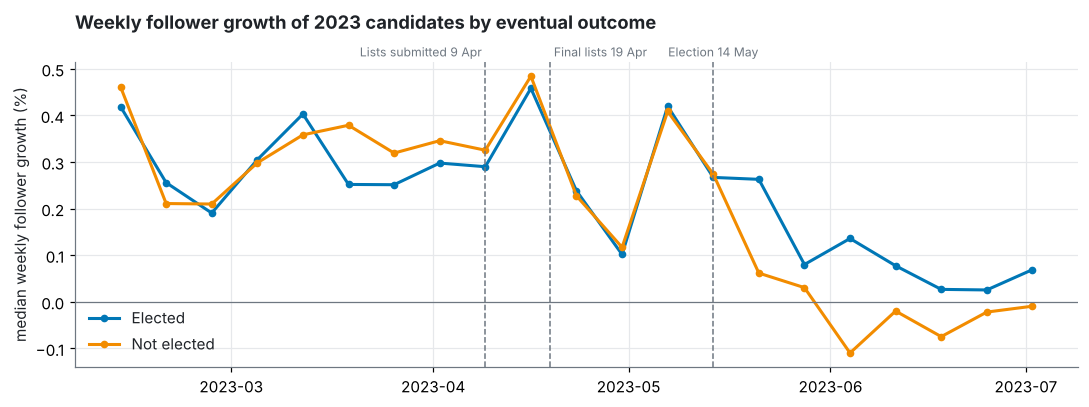

Change in weekly growth after lists, electable vs not: 0.010 vs -0.008 pp/week (p = 0.63)


In [6]:
wk = d.merge(t[['elected_']], left_on='id', right_index=True)
wk = wk[wk.date >= '2023-02-01'].sort_values('date')
wk = wk.groupby(['id', pd.Grouper(key='date', freq='W')]).followers.last().groupby(level=0).pct_change().mul(100).rename('wg').reset_index()
wk = wk.merge(t[['elected_']], left_on='id', right_index=True)
path = wk.groupby(['elected_', 'date']).wg.median().unstack(0)

fig, ax = plt.subplots(figsize=(10, 3.8))
for grp, col in [('Elected', WIN), ('Not elected', LOSE)]:
    ax.plot(path.index, path[grp], color=col, lw=2, marker='o', ms=4, label=grp)
for lab, day, ha in [('Lists submitted 9 Apr ', '2023-04-09', 'right'), (' Final lists 19 Apr', '2023-04-19', 'left'),
                     ('Election 14 May', '2023-05-14', 'center')]:
    ax.axvline(pd.Timestamp(day), color=MUTED, ls='--', lw=1)
    ax.text(pd.Timestamp(day), 1.01, lab, transform=ax.get_xaxis_transform(), ha=ha, va='bottom', fontsize=8, color=MUTED)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylabel('median weekly follower growth (%)')
ax.set_title('Weekly follower growth of 2023 candidates by eventual outcome', pad=22)
ax.legend(frameon=False, loc='lower left')
plt.tight_layout(); plt.savefig(FIG / '08_weekly_growth_candidates.png', dpi=200); plt.show()

t['accel'] = t.growth_campaign / 5 - t.growth_prelist / 2   # %/week after lists minus %/week before
a, b = t.loc[t.margin <= 0, 'accel'].dropna(), t.loc[t.margin >= 1, 'accel'].dropna()
print(f"Change in weekly growth after lists, electable vs not: {a.median():.3f} vs {b.median():.3f} pp/week (p = {stats.mannwhitneyu(a, b).pvalue:.2f})")

The two groups move **in parallel** through the campaign — no visible extra boost for safe-slot candidates once
lists were public. The paths only **separate after election day**.

## 5 · H2c — Seat effect: regression discontinuity at the cutoff
Near the cutoff, whether rank *r* gets a seat depends on how many votes the whole list won in the district — something
the individual candidate barely controls. Comparing candidates just inside (margin 0, −1, …) with those just outside
(margin 1, 2, …) therefore approximates **the effect of winning a seat** on follower growth.
Local linear fit on each side within a bandwidth, bootstrap 95% CI. **Placebo:** the same design on *pre-election*
growth should show **no** jump.

In [7]:
def rd(df, outcome, bw=3, n_boot=2000, seed=0):
    x = df[df.margin.between(-bw + 1, bw)].dropna(subset=[outcome])
    xv = x.margin.values - 0.5; y = x[outcome].clip(*x[outcome].quantile([.01, .99])).values
    def est(xv, y):
        L, R = xv < 0, xv > 0
        bl = np.polyfit(xv[L], y[L], 1); br = np.polyfit(xv[R], y[R], 1)
        return np.polyval(bl, 0) - np.polyval(br, 0)   # winners minus losers at the cutoff
    point = est(xv, y)
    rng = np.random.default_rng(seed); boots = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if (xv[i] < 0).sum() > 5 and (xv[i] > 0).sum() > 5:
            boots.append(est(xv[i], y[i]))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return dict(outcome=outcome, bandwidth=bw, n_in=(xv < 0).sum(), n_out=(xv > 0).sum(),
                jump_pp=round(point, 2), ci_low=round(lo, 2), ci_high=round(hi, 2))

res = pd.DataFrame([rd(t, o, bw) for o in ['growth_postelect', 'growth_campaign', 'growth_pre'] for bw in (2, 3, 4)])
display(res)

,outcome,bandwidth,n_in,n_out,jump_pp,ci_low,ci_high
0,growth_postelect,2,142,52,2.49,0.75,4.49
1,growth_postelect,3,176,61,1.77,0.42,3.27
2,growth_postelect,4,203,65,1.55,0.37,2.78
3,growth_campaign,2,144,53,-2.08,-4.63,0.27
4,growth_campaign,3,178,63,-1.43,-3.71,0.74
5,growth_campaign,4,205,67,-1.20,-3.61,0.86
6,growth_pre,2,144,53,1.53,-1.43,4.35
7,growth_pre,3,178,63,0.09,-2.54,2.44
8,growth_pre,4,205,67,-0.08,-2.36,1.95


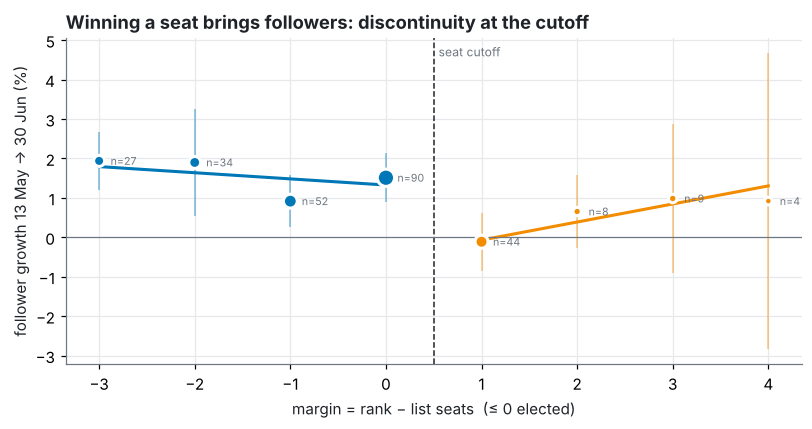

dots = mean growth per margin (winsorised), bars = 95% CI, lines = local linear fits used in the RD estimate


In [8]:
# Same data as the RD estimate with bandwidth 4: outcome winsorised at 1%/99%, margins -3..4
bw = 4
sub = t[t.margin.between(-bw + 1, bw)].dropna(subset=['growth_postelect']).copy()
sub['y'] = sub.growth_postelect.clip(*sub.growth_postelect.quantile([.01, .99]))
m = sub.groupby('margin').y.agg(['mean', 'count', 'sem'])
fig, ax = plt.subplots(figsize=(7.5, 4))
for side, col in [((-bw + 1, 0), WIN), ((1, bw), LOSE)]:
    s_ = sub[sub.margin.between(*side)]
    b = np.polyfit(s_.margin, s_.y, 1); xs = np.linspace(side[0], side[1], 20)
    ax.plot(xs, np.polyval(b, xs), color=col, lw=2, zorder=2)
    mm = m.loc[side[0]:side[1]]
    ax.errorbar(mm.index, mm['mean'], yerr=1.96 * mm['sem'].fillna(0), fmt='none', ecolor=col, elinewidth=1, alpha=0.5)
    ax.scatter(mm.index, mm['mean'], s=20 + mm['count'] * 1.2, color=col, edgecolor='white', linewidth=2, zorder=3)
    for v, r in mm.iterrows():
        ax.text(v + 0.12, r['mean'], f"n={int(r['count'])}", fontsize=7, color=MUTED, va='center')
ax.axvline(0.5, color=INK, ls='--', lw=1); ax.axhline(0, color=MUTED, lw=0.8)
ax.text(0.55, 0.98, 'seat cutoff', transform=ax.get_xaxis_transform(), fontsize=8, color=MUTED, va='top')
ax.set_xticks(range(-bw + 1, bw + 1))
ax.set_xlabel('margin = rank − list seats  (≤ 0 elected)'); ax.set_ylabel('follower growth 13 May → 30 Jun (%)')
ax.set_title('Winning a seat brings followers: discontinuity at the cutoff')
plt.tight_layout(); plt.savefig(FIG / '09_rd_seat_effect.png', dpi=200); plt.show()
print('dots = mean growth per margin (winsorised), bars = 95% CI, lines = local linear fits used in the RD estimate')

## 6 · Take-aways for the final project
| Question | Preliminary answer | Next step |
|---|---|---|
| H2a Selection | Larger accounts get better ranks (AKP ρ ≈ −0.35, YSGP ≈ −0.5); recent growth does **not**, except possibly in CHP | add seniority controls (incumbent, minister, party post) in a logistic model |
| H2b Anticipation | No extra growth for electable slots between list publication and election | formal difference-in-differences with person fixed effects |
| H2c Seat effect | Clear positive jump in post-election growth at the cutoff; placebo on pre-election growth is the key check | report robustness over bandwidths; cluster by district |

**Limitations:** the #Secim2023 account list over-represents incumbents (few true newcomers); OCR + name matching may
mislink a handful of common names; Twitter "followers" are attention, not approval.